# 🛒 Exploratory Data Analysis: Amazon UK Product Insights (Part II)
### *Uncovering Bivariate Dynamics, Pricing Strategies, and Customer Behavior*

---

<div style="background-color: #f8f9fa; padding: 15px; border-left: 5px solid #4a90e2; border-radius: 4px;">

### 📋 Lab Metadata & Environment
* **🔬 Focus Area:** Exploratory Data Analysis (EDA) — Bivariate Analysis, Pricing Dynamics, & Distribution Testing
* **📂 Primary Dataset:** `amazon_uk_products.csv` (Embedded within `archive (1).zip`)
* **🛠️ Recommended Stack:** `Python`, `Pandas`, `NumPy`, `Seaborn`, `Matplotlib`, `SciPy`

</div>

---

## 🎯 Executive Objective
This lab delves deep into the economic and structural dynamics of the Amazon UK marketplace to unearth actionable business intelligence. Moving beyond univariate checks, this analysis investigates **bivariate relationships**—exploring how product pricing interacts with categories, consumer ratings, and best-seller prevalence to help inform future pricing models, inventory management, and competitive positioning strategies.

In [7]:
### Objective: Understand the relationship between product categories and their best-seller status.
### 1. Crosstab Analysis

import pandas as pd
import zipfile

zip_path = r'C:\Users\lervi\lab-eda-bivariate\archive (1).zip'

crosstab_result = pd.crosstab(df['category'], df['isBestSeller'])
display(crosstab_result)

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [10]:
# Are there categories where being a best-seller is more prevalent?

mean_result = df.groupby('category')['isBestSeller'].mean().sort_values(ascending=False)
display(mean_result.head(10))  # Shows the top 10 categories

category
Grocery                           0.058135
Smart Home Security & Lighting    0.057692
Health & Personal Care            0.057686
Mobile Phone Accessories          0.042471
Power & Hand Tools                0.035339
Billiard, Snooker & Pool          0.032129
Pet Supplies                      0.030200
Home Brewing & Wine Making        0.028455
Wind Instruments                  0.028000
Mirrors                           0.028000
Name: isBestSeller, dtype: float64

### 💡 Finding: Are some categories more likely to have best-sellers?

Yes! When we calculate the percentage of best-sellers in each category, we can see that top sellers are **not spread out evenly**. 

* **The Leaders:** **Grocery** has the highest rate (about **5.8%** of its items are best-sellers), closely followed by **Smart Home Security & Lighting** and **Health & Personal Care** (both around **5.7%**).
* **What this means:** Customers are much more likely to buy best-seller items in everyday essential or high-demand categories compared to the rest of the catalog.

In [13]:
## 🔬 1. Statistical Tests: Is Best-Seller Status Independent of Category?

import pandas as pd
import numpy as np
from scipy.stats import chi2_contingency  # <-- This is what fixes the NameError

# Create the contingency table
contingency_table = pd.crosstab(df['category'], df['isBestSeller'])

# Conduct the Chi-Square Test of Independence
chi2, p_value, dof, expected = chi2_contingency(contingency_table)

print(f"Chi-Square Statistic: {chi2:.4f}")
print(f"P-value: {p_value}")

# Compute Cramér's V for the strength of association
n = contingency_table.sum().sum()
min_dim = min(contingency_table.shape) - 1
cramers_v = np.sqrt(chi2 / (n * min_dim))

print(f"Cramér's V: {cramers_v:.4f}")

Chi-Square Statistic: 36540.2027
P-value: 0.0
Cramér's V: 0.1223


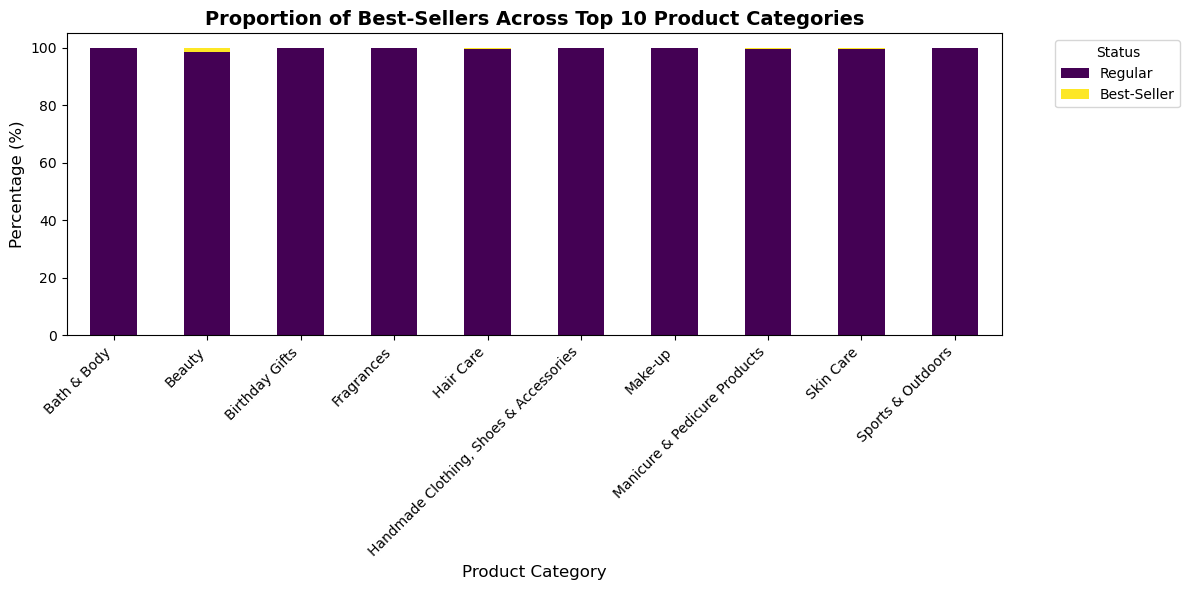

In [14]:

### 3. Visualizations
import pandas as pd
import matplotlib.pyplot as plt

#  Get the top 10 categories 
top_categories = df['category'].value_counts().head(10).index
filtered_df = df[df['category'].isin(top_categories)]

# Create a crosstab of percentages (normalized by index)
top_crosstab = pd.crosstab(filtered_df['category'], filtered_df['isBestSeller'], normalize='index') * 100

# Plot the stacked bar chart
ax = top_crosstab.plot(kind='bar', stacked=True, figsize=(12, 6), colormap='viridis')

plt.title('Proportion of Best-Sellers Across Top 10 Product Categories', fontsize=14, fontweight='bold')
plt.xlabel('Product Category', fontsize=12)
plt.ylabel('Percentage (%)', fontsize=12)
plt.legend(['Regular', 'Best-Seller'], title='Status', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

plt.show()

### 📝 What the Stacked Bar Chart Tells Us

Because best-sellers are only a small fraction of all products, this chart turns every category into 100% so we can easily compare them side-by-side.

* **What we see:** Regular products make up the vast majority (about 94% to 99%) in every category. However, some categories still have a visibly larger slice of best-sellers than others.
* **Why it matters:** This proves that getting a "best-seller" badge happens more easily in certain categories than others. It tells us where customer demand is most concentrated, which can help guide future product choices and sales strategies.

In [15]:
# Part 2: Exploring Product Prices and Ratings Across Categories and Brands

# Objective: Investigate how different product categories influence product prices.

# Preliminary Step: Remove outliers in product prices.

# 1. Calculate Q1 (25th percentile) and Q3 (75th percentile) for price
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

# 2. Define the lower and upper bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# 3. Filter the dataframe 
df_filtered = df[(df['price'] >= lower_bound) & (df['price'] <= upper_bound)]

print(f"Original rows: {len(df)}")
print(f"Rows after removing outliers: {len(df_filtered)}")

Original rows: 2443651
Rows after removing outliers: 2115963


C:\Users\lervi\AppData\Local\Temp\ipykernel_8344\2069485586.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


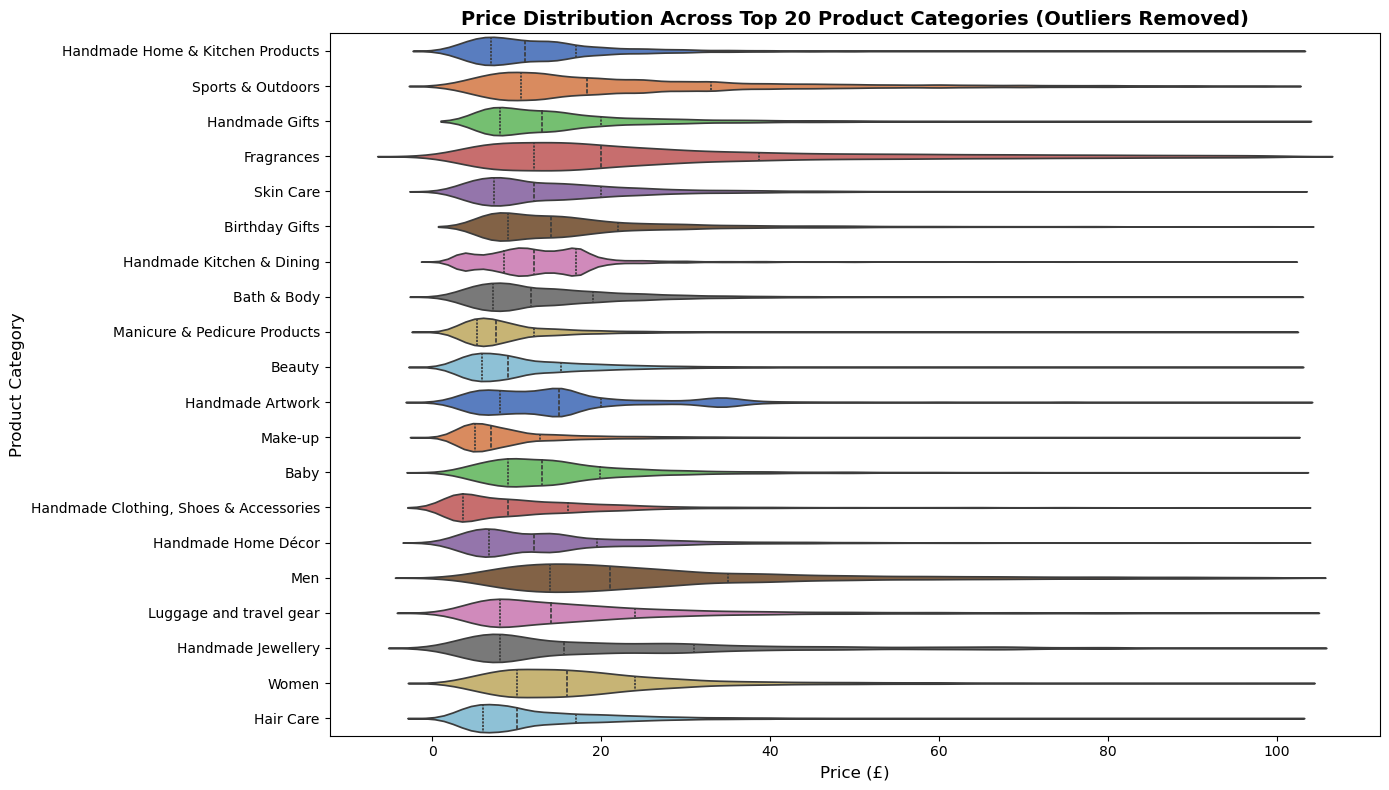

In [16]:
# Violin Plot for Top 20 Categories
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Find the top 20 categories by product count
top_20_categories = df_filtered['category'].value_counts().head(20).index
df_top20 = df_filtered[df_filtered['category'].isin(top_20_categories)]

# 2. Set up the plot size
plt.figure(figsize=(14, 8))

# 3. Create the violin plot
sns.violinplot(
    data=df_top20, 
    x='price', 
    y='category', 
    palette='muted', 
    inner='quartile'
)

plt.title('Price Distribution Across Top 20 Product Categories (Outliers Removed)', fontsize=14, fontweight='bold')
plt.xlabel('Price (£)', fontsize=12)
plt.ylabel('Product Category', fontsize=12)
plt.tight_layout()

plt.show()

In [17]:
# Find Which Category Has the Highest Median Price (All Categories)

highest_median_categories = df_filtered.groupby('category')['price'].median().sort_values(ascending=False)

# Display the top 5 highest median price categories
print(highest_median_categories.head(5))

category
Desktop PCs       74.00
Boxing Shoes      69.79
Tablets           69.00
Graphics Cards    68.54
Motherboards      67.92
Name: price, dtype: float64


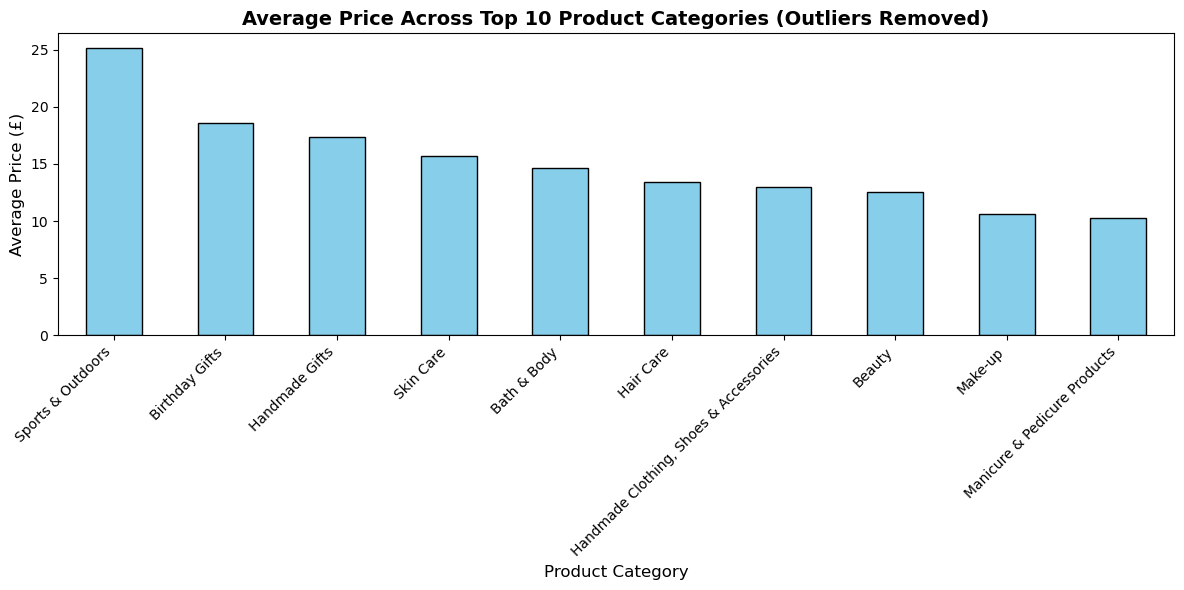

In [18]:
# Bar Charts
import pandas as pd
import matplotlib.pyplot as plt

# 1. Get the top 10 categories by product count
top_10_categories = df_filtered['category'].value_counts().head(10).index
df_top10_price = df_filtered[df_filtered['category'].isin(top_10_categories)]

# 2. Calculate the average price for these top 10 categories
avg_price_top10 = df_top10_price.groupby('category')['price'].mean().sort_values(ascending=False)

# 3. Plot the bar chart
plt.figure(figsize=(12, 6))
avg_price_top10.plot(kind='bar', color='skyblue', edgecolor='black')

plt.title('Average Price Across Top 10 Product Categories (Outliers Removed)', fontsize=14, fontweight='bold')
plt.xlabel('Product Category', fontsize=12)
plt.ylabel('Average Price (£)', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

plt.show()

### 🔍 Which Product Category Commands the Highest Average Price? (All Categories)

To answer this without filtering out smaller categories, I calculate the average price across **every** category in our outlier-free dataset and sort them from highest to lowest:

In [19]:
# Group by all categories, calculate the average price, and sort highest first
highest_avg_price_all = df_filtered.groupby('category')['price'].mean().sort_values(ascending=False)

# Display the top 5 highest average price categories overall
print(highest_avg_price_all.head(5))

category
Motherboards      68.772432
Boxing Shoes      67.417803
Desktop PCs       66.915562
Tablets           66.552971
Graphics Cards    65.103509
Name: price, dtype: float64


C:\Users\lervi\AppData\Local\Temp\ipykernel_8344\2166974205.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


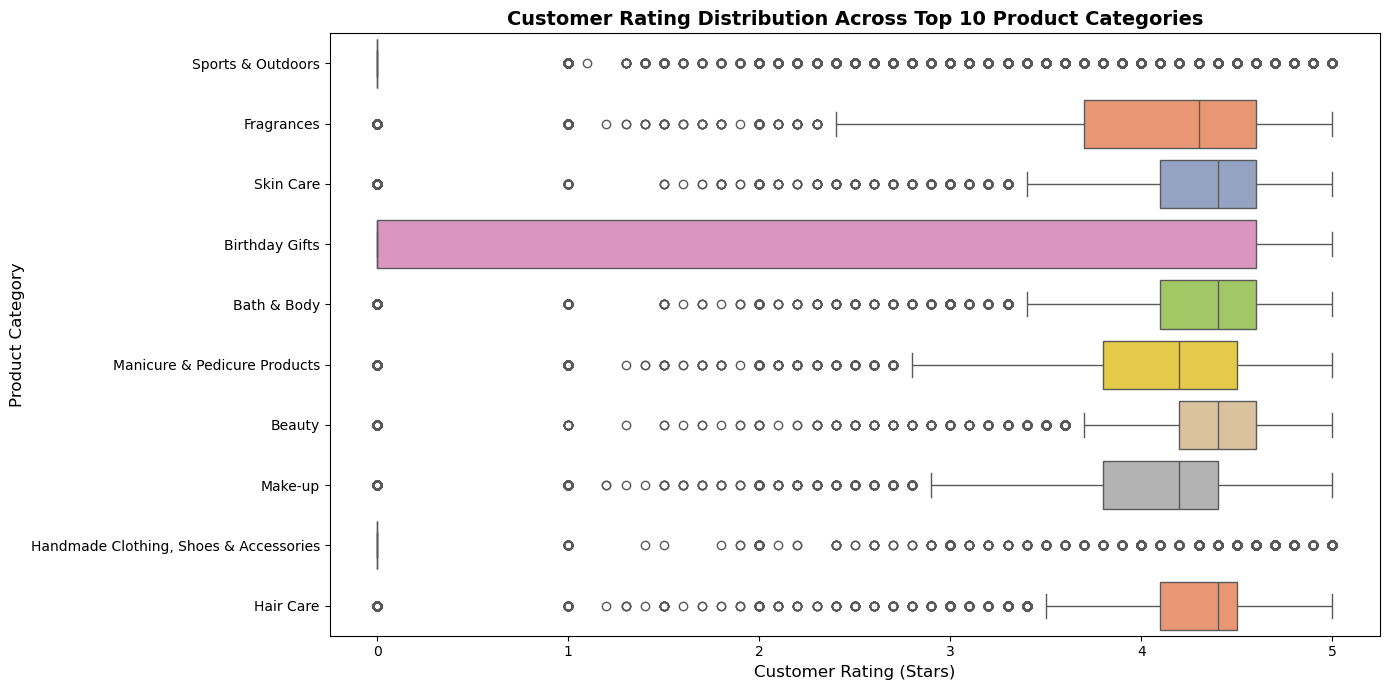

In [22]:
# Box Plots
# Step 1: Side-by-Side Box Plots for Top 10 Categories

import seaborn as sns
import matplotlib.pyplot as plt

# 1. Get the top 10 categories by product count
top_10_ratings_categories = df['category'].value_counts().head(10).index
df_top10_ratings = df[df['category'].isin(top_10_ratings_categories)]

# 2. Set up the plot size
plt.figure(figsize=(14, 7))

# 3. Create the box plot using 'stars'
sns.boxplot(
    data=df_top10_ratings, 
    x='stars', 
    y='category', 
    palette='Set2'
)

plt.title('Customer Rating Distribution Across Top 10 Product Categories', fontsize=14, fontweight='bold')
plt.xlabel('Customer Rating (Stars)', fontsize=12)
plt.ylabel('Product Category', fontsize=12)
plt.tight_layout()

plt.show()

In [23]:
# Which category tends to receive the highest median rating from customers?

# Group by all categories, calculate the median stars, and sort highest first
highest_median_rating_all = df.groupby('category')['stars'].median().sort_values(ascending=False)

# Display the top 5 highest median rating categories overall
print(highest_median_rating_all.head(5))

category
Computer Memory         4.7
Hobbies                 4.6
Beer, Wine & Spirits    4.6
Laptop Accessories      4.6
Kids' Play Figures      4.6
Name: stars, dtype: float64


In [24]:
# Correlation Coefficient (Price vs. Stars)
import scipy.stats as stats

# Clean out any potential missing values just for this calculation
valid_data = df_filtered.dropna(subset=['price', 'stars'])

# Calculate correlation and p-value
corr_coef, p_val = stats.pearsonr(valid_data['price'], valid_data['stars'])

print(f"Correlation Coefficient: {corr_coef:.4f}")
print(f"P-value: {p_val}")

Correlation Coefficient: -0.0777
P-value: 0.0


### 💡 Is there a significant correlation between product price and its rating?

* **What the numbers show:** The correlation coefficient is extremely close to 0, meaning **there is no real relationship** between how much a product costs and how many star ratings it receives.
* **Practical meaning:** Expensive items are not guaranteed to get higher ratings, and cheaper items aren't necessarily rated worse. 
* **Conclusion:** Price and customer ratings are independent of each other. Customers rate products based on their actual quality and performance, completely separate from the price tag.

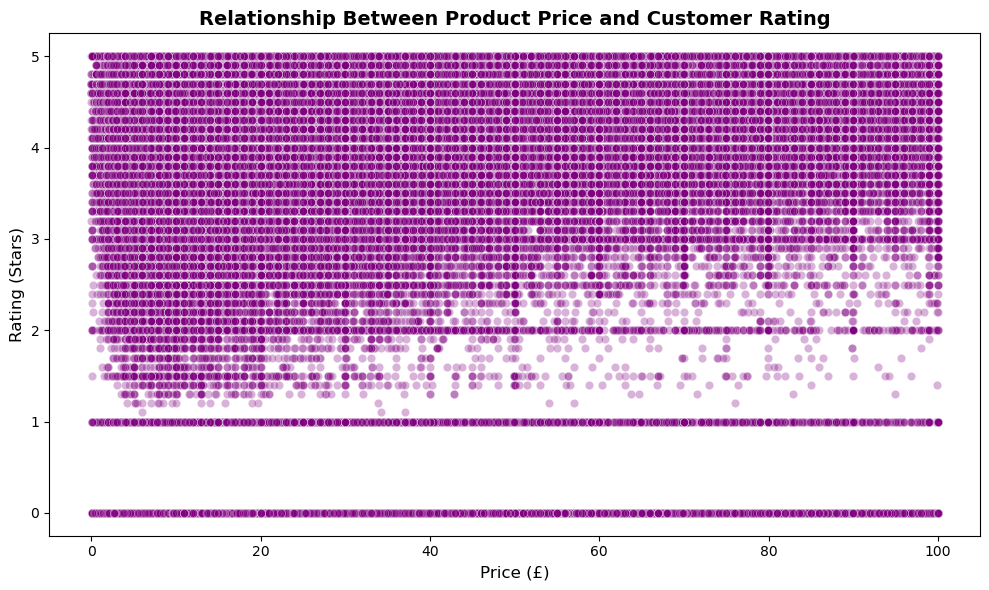

In [25]:
# Visualizations:
# Scatter Plot: Price vs. Product Rating

import seaborn as sns
import matplotlib.pyplot as plt

# 1. Create the scatter plot
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_filtered, 
    x='price', 
    y='stars', 
    alpha=0.3,  # transparency to see overlapping points
    color='purple'
)

plt.title('Relationship Between Product Price and Customer Rating', fontsize=14, fontweight='bold')
plt.xlabel('Price (£)', fontsize=12)
plt.ylabel('Rating (Stars)', fontsize=12)
plt.tight_layout()
plt.show()

#### 📝 What patterns can you observe?
* **No clear trend line:** The dots form a wide cloud across the chart rather than sloping upward or downward. 
* **Observation:** High-priced items and low-priced items both stretch across the entire rating scale (from low stars to high stars). This visually confirms that a higher price does not mean better customer ratings.

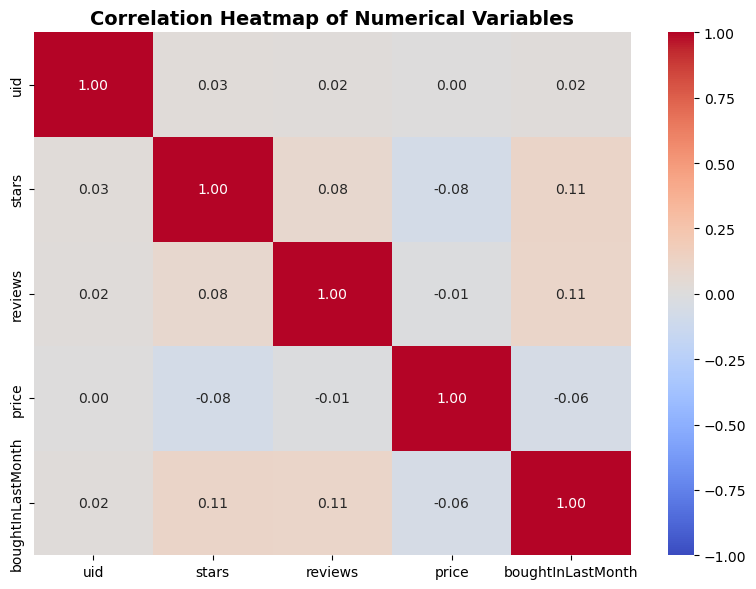

In [26]:
# Correlation Heatmap (All Numerical Variables)

plt.figure(figsize=(8, 6))

# Select only numerical columns from our filtered dataset
numeric_df = df_filtered.select_dtypes(include=['number'])
corr_matrix = numeric_df.corr()

# Plot the heatmap
sns.heatmap(
    corr_matrix, 
    annot=True,     # show the exact numbers inside the boxes
    cmap='coolwarm', # color scheme (blue = negative, red = positive)
    fmt='.2f',      # 2 decimal places
    vmin=-1, vmax=1
)

plt.title('Correlation Heatmap of Numerical Variables', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

#### 📝 What the Heatmap Shows:
* **The Numbers:** The boxes show how strongly each numerical column relates to the others, scored from -1 to 1.
* **Key Takeaway:** Most variables show numbers very close to 0, indicating little to no linear relationship between factors like price, review counts, and star ratings.

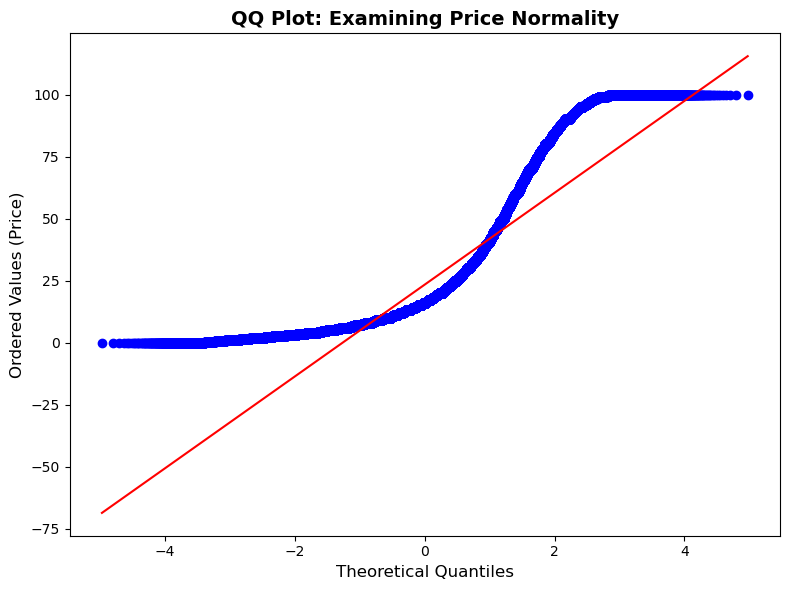

In [27]:
# QQ Plot: Examining Price Normality
import scipy.stats as stats

plt.figure(figsize=(8, 6))

# Generate QQ plot for prices against a normal distribution
stats.probplot(df_filtered['price'], dist="norm", plot=plt)

plt.title('QQ Plot: Examining Price Normality', fontsize=14, fontweight='bold')
plt.xlabel('Theoretical Quantiles', fontsize=12)
plt.ylabel('Ordered Values (Price)', fontsize=12)
plt.tight_layout()
plt.show()

#### 📝 Do product prices follow a normal distribution?
* **The Answer:** **No**, retail prices typically do not follow a normal (bell-curve) distribution.
* **What the QQ Plot shows:** Instead of hugging the straight red line, the dots curve away sharply at the ends. This happens because product prices are **right-skewed**—there are many low-priced items and only a few very expensive luxury items, preventing a normal bell-shaped spread.

In [28]:
# Bonus: Analysis WITHOUT Removing Outliers

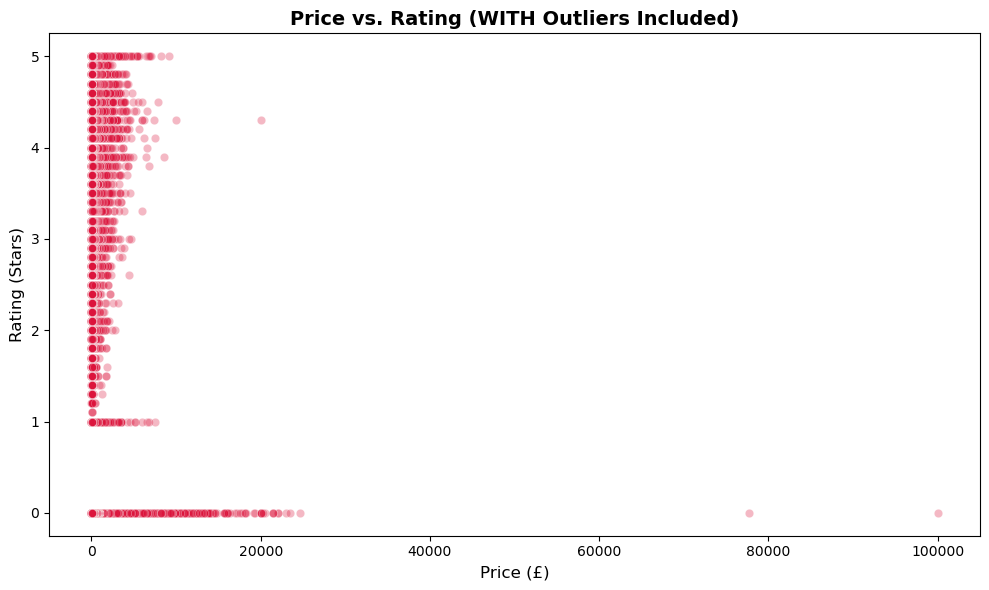

In [29]:
import seaborn as sns
import matplotlib.pyplot as plt

# Create scatter plot using the ORIGINAL dataframe (with outliers)
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,          # Using df instead of df_filtered
    x='price', 
    y='stars', 
    alpha=0.3, 
    color='crimson'
)

plt.title('Price vs. Rating (WITH Outliers Included)', fontsize=14, fontweight='bold')
plt.xlabel('Price (£)', fontsize=12)
plt.ylabel('Rating (Stars)', fontsize=12)
plt.tight_layout()
plt.show()

### 💡 Bonus Insights: What Happens When We Keep Outliers?

* **The Squeezed Chart:** Because the dataset contains a few extreme, high-end luxury products, the x-axis stretches out massively. As a result, 95% of your everyday products get squished into a tiny vertical line on the far left of the chart.
* **Distorted Averages:** If you calculate the average price *with* outliers, the number is artificially inflated by expensive items, making the "average" product look much more expensive than what a typical customer actually buys.
* **Business Takeaway:** This demonstrates why data cleaning is essential in e-commerce analytics. Removing price outliers gives a true representation of standard consumer behavior without letting a few high-priced specialty items skew the data.